# T6: Retrieval design study and proof of concept

This notebook is the design document and proof of concept (POC) for the brief's extrinsic evaluation (T6): *"a
retrieval/agent that starts at a coarse level and drills down to find target nodes, versus a flat baseline, scored on
hit-rate or steps-to-target"*. It does four things:

1. It studies the format of the questions (`data/questions.csv`) and the ground-truth answers
   (`data/ground_truth.json`) (§2–§3).
2. It maps the ground truth onto the graph and measures what the export can answer at all (§4).
3. It describes the coarsening hierarchy as a search index (§5).
4. It proposes a simple POC agent with a flat baseline (§6), defines the metrics (§7), runs both on all 18 questions
   (§8), and lists guidelines for the implementation (§9).

**Inputs:**
- the run configuration (`configs/default.toml` or `$TKH_CONFIG`);
- the graph export;
- the run's hierarchies, `out/<cutoff>/hierarchy.json`, which are read, never rebuilt;
- the two data files.

The POC functions are defined here on purpose: they are a reference for the rewrite, not the shipped module. Only
stable library code is imported (`tkh.io`, `tkh.semantic`, `tkh.config`, and the constant `CLUSTER_RELATIONS` from
`tkh.coarsen`). There are no LLM calls and no network.

### Requirements from the brief and where they are met

| Requirement (brief) | Where | Status |
|---|---|---|
| T6: start coarse, drill down to target nodes, vs a flat baseline | §6 agent and flat baseline | implemented (POC) |
| T6: hit-rate or steps-to-target | §7 definitions, §8 results | implemented (both); the result is negative for this POC (§9) |
| "Intrinsic metrics alone are not enough" | the whole notebook | — |
| P6 temporal honesty: nothing beyond the snapshot's cutoff | §2 snapshot rule, §6 snapshot-only node text, §7 temporal compliance | implemented; the 18 questions all map to ≤2026, so the earlier-snapshot path is checked separately in §6; aliases are undated (gap) |
| Circularity: no grading with the ruler that built the clusters | §6 similarity choice (word TF-IDF, not the char-n-gram name LSA of clustering) | partly: overlap stated |
| Null models: a number relative to chance | §7–§8 random-tree null, label-free ablation | implemented |
| CIs / significance, not point estimates | §7 paired bootstrap over questions | implemented |
| Data: Option A export (§4), which holds no paper text; using only it is this project's choice | §3 field roles (`locations`, `venue` not scorable) | by construction |
| §7: verified vs assumed, flag uncertainty | §9 | stated |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "tkh").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from collections import Counter, defaultdict
import json
import re
import unicodedata

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize

from tkh.coarsen import CLUSTER_RELATIONS
from tkh.config import load_config
from tkh.io import load, snapshot
from tkh import semantic as sm

MPL = tuple(int(x) for x in matplotlib.__version__.split(".")[:2])
print(f"python {sys.version.split()[0]}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

cfg = load_config()  # honours $TKH_CONFIG
CUTOFFS, RUN, FIG = cfg.cutoffs, cfg.out_dir, cfg.figures_dir
FIG.mkdir(parents=True, exist_ok=True)
QUESTIONS, GT_PATH = ROOT / "data" / "questions.csv", ROOT / "data" / "ground_truth.json"
tkh = load(cfg)
H = {c: json.loads((RUN / str(c) / "hierarchy.json").read_text()) for c in CUTOFFS}
print(f"config: {cfg.source}\nrun: {RUN}\n{len(tkh.nodes)} nodes, {len(tkh.edges)} hyper-edges, "
      f"{len(tkh.articles)} articles; cutoffs {CUTOFFS}")

python 3.12.11, pandas 3.0.6, matplotlib 3.11.2
config: /Users/alexeyr/Personal/TKH/repo/configs/default.toml
run: /Users/alexeyr/Personal/TKH/repo/out
5798 nodes, 1429 hyper-edges, 52 articles; cutoffs (2020, 2022, 2024, 2026)


## 2. Questions: `data/questions.csv`

The file is `;`-separated with three columns: `question_id`, `question` and `type`. The type is metadata. A means
*specific search*: the answer is a list of methods (or datasets) plus their citations. B means *synthesis of
evidence*: the answer is a list of claims plus their citations.

The questions are written to a few templates. Most name an as-of date in parentheses ("by Feb 2026"). The cell below
parses, for each question:
- the template;
- the task phrase (after "for", before "when");
- the condition clause (after "when");
- the date cue.

In [2]:
qdf = pd.read_csv(QUESTIONS, sep=";", dtype=str)
print(qdf.shape, list(qdf.columns), dict(qdf["type"].value_counts()))

MONTHS = "jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec"
DATE = re.compile(rf"\b(?:by|as of|before|until|up to)\s+(?:(?:{MONTHS})[a-z]*\.?\s+)?((?:19|20)\d\d)\b", re.I)
TEMPLATES = [("which methods ... best suited for X [when Y]", r"^which methods .*best suited for "),
             ("what are the leading X", r"^what are the leading"),
             ("what datasets and benchmarks", r"^what datasets"),
             ("what are the most important open challenges", r"^what are the most important"),
             ("how does X improve Y", r"^how does"),
             ("give evidence that X", r"^give evidence"),
             ("what mechanisms ... and what evidence", r"^what mechanisms")]


def choose_snapshot(question, cutoffs=CUTOFFS):
    # Latest cutoff <= the stated year; no date -> the latest cutoff (the source is recorded).
    m = DATE.search(question)
    if not m:
        return max(cutoffs), None, "default_latest"
    year = int(m.group(1))
    ok = [c for c in sorted(cutoffs) if c <= year]
    return (ok[-1], year, "stated") if ok else (None, year, "before_first_cutoff")   # no snapshot: abstain


def parse(q):
    low = q.lower()
    tpl = next((name for name, rx in TEMPLATES if re.search(rx, low)), "other")
    task = re.search(r"\bfor (.+?)(?:\bwhen\b|\?|$)", re.sub(r"\([^)]*\)", "", q), re.I)
    cond = re.search(r"\bwhen (.+?)(?:\?|$)", q, re.I)
    date = re.search(r"\(([^)]*\d{4}[^)]*)\)", q)
    return tpl, task.group(1).strip() if task else "", cond.group(1).strip() if cond else "", date.group(1) if date else ""


rows = []
for _, r in qdf.iterrows():
    tpl, task, cond, date = parse(r["question"])
    snap, year, src = choose_snapshot(r["question"])
    rows.append({"id": r["question_id"], "type": r["type"], "words": len(r["question"].split()), "template": tpl,
                 "date cue": date, "as-of year": year, "snapshot": snap, "snapshot source": src,
                 "task phrase": task[:60], "condition": cond[:60]})
Q = pd.DataFrame(rows).set_index("id")
print("edge cases:", {t: choose_snapshot(t) for t in ("Which methods (by March 2023) work?", "Which methods by 2019?", "How does X work?")})
Q

(18, 3) ['question_id', 'question', 'type'] {'A': np.int64(14), 'B': np.int64(4)}
edge cases: {'Which methods (by March 2023) work?': (2022, 2023, 'stated'), 'Which methods by 2019?': (None, 2019, 'before_first_cutoff'), 'How does X work?': (2026, None, 'default_latest')}


,type,words,template,date cue,as-of year,snapshot,snapshot source,task phrase,condition
id,,,,,,,,,
Q1,A,27,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting interatomic potentials,balancing accuracy close to DFT with computational efficienc
Q2,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,accelerating electronic structure calculations,self-consistent field iterations become prohibitively expens
Q3,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,learning DFT Hamiltonians,dealing with twisted van der Waals heterostructures containi
Q4,A,21,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,phonon property prediction,universal MLIPs show inaccuracies despite good energy/force
Q5,A,22,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,coarse-graining molecular dynamics,crystalline symmetries and long-range elastic interactions m
Q6,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting ionic conductivity,full ab initio MD is too expensive but accuracy must be main
Q7,A,20,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting phase transitions,"screening ~50,000 inorganic compounds at high throughput"
Q8,A,22,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting fracture patterns,generalizing from atomistic MD data to unseen bicrystalline
Q9,A,21,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,ensuring physical consistency,transferring information between scales without violating th


**Observations:**
- **Templates.** Q1–Q11 share one template, "which methods … best suited for <task> when <condition>"; Q11 has no
  condition. Q12–Q14 ask for the leading methods or datasets. Q15–Q18 are synthesis questions with four different
  templates.
- **Dates.** Every question but Q16 states "by Feb 2026". Q16 has no date cue, so it gets the latest snapshot, and
  this is recorded.
- **Snapshot granularity.** Snapshots are yearly (cutoffs 2020/2022/2024/2026). "Feb 2026" maps to the ≤2026
  snapshot, which cannot exclude papers published later in 2026; §4 checks how many there are.

**Design choice D1, snapshot rule:** the latest cutoff not after the stated year; no date → the latest cutoff; a date
before the first cutoff → no snapshot, so the agent abstains.
- Rationale: it never uses content after the question's date (P6), and it is deterministic.
- Rejected: always the latest snapshot, which would leak for earlier dates. Interpolating between snapshots isn't
  possible, because snapshots are cumulative and cut by year.
- Trade-off: within-year granularity is lost.

## 3. Ground truth: `data/ground_truth.json`

The file is a dict keyed by question id, and every entry has a `type`. The cells below inventory every field at every
nesting level, check the cross-references between fields, and assign each field a role in the evaluation.

In [3]:
gt = json.loads(GT_PATH.read_text())
A = {q: v for q, v in gt.items() if v["type"] == "A"}
B = {q: v for q, v in gt.items() if v["type"] == "B"}
assert set(gt) == set(qdf["question_id"]) and all(gt[q]["type"] == t for q, t in zip(qdf["question_id"], qdf["type"]))


def presence(entries):
    keys = sorted({k for v in entries for k in v})
    return pd.Series({k: sum(k in v for v in entries) for k in keys}, name=f"present in (of {len(entries)})")


print("type A, top level:"); display(presence(list(A.values())).to_frame())
print("type A, method_evidence items:"); display(presence([e for v in A.values() for m in v["method_evidence"].values() for e in m]).to_frame())
print("type A, fp_categories:"); display(presence([v["fp_categories"] for v in A.values() if "fp_categories" in v]).to_frame())
print("type B, top level:"); display(presence(list(B.values())).to_frame())
print("type B, required_claims items:"); display(presence([c for v in B.values() for c in v["required_claims"]]).to_frame())
print("type B, sources items:"); display(presence([s for v in B.values() for s in v["sources"].values()]).to_frame())

type A, top level:


,present in (of 14)
expected_methods,14
fp_categories,12
method_claims,14
method_evidence,14
required_citations,14
type,14


type A, method_evidence items:


,present in (of 188)
evidence,188
location,188
source,188


type A, fp_categories:


...

,present in (of 4)
as_of,4
contrast_sources,1
provenance_policy,1
required_citations,4
required_claims,4
sources,4
type,4


type B, required_claims items:


,present in (of 36)
caveat,23
contrast,1
coverage,36
distractor_note,7
evidence,36
flag,12
id,36
independence,6
locations,33
regime_scope,2


type B, sources items:


,present in (of 19)
date,19
doi,12
evidence_type,19
key,19
note,14
title,19
venue,19
verification,2
verified,5


In [4]:
def a_row(q, v):
    fp = v.get("fp_categories", {})
    return {"expected_methods": len(v["expected_methods"]), "method_claims": sum(map(len, v["method_claims"].values())),
            "method_evidence": sum(map(len, v["method_evidence"].values())), "required_citations": len(v["required_citations"]),
            "wrong_domain": len(fp.get("wrong_domain", [])), "outdated_as_main": len(fp.get("outdated_as_main", [])),
            "valid_but_unlisted": len(fp.get("valid_but_unlisted", [])), "has fp_categories": "fp_categories" in v}


def b_row(q, v):
    cl = v["required_claims"]
    return {"as_of": v["as_of"], "sources": len(v["sources"]), "required_claims": len(cl),
            **{f"coverage={c}": sum(x["coverage"] == c for x in cl) for c in ("full", "partial", "asserted_only")},
            "multi-source claims": sum(len(x["sources"]) > 1 for x in cl),
            "with independence": sum("independence" in x for x in cl), "with distractor_note": sum("distractor_note" in x for x in cl),
            "with contrast": sum("contrast" in x for x in cl), "required_citations": len(v["required_citations"]),
            "contrast_sources": len(v.get("contrast_sources", {}))}


display(pd.DataFrame({q: a_row(q, v) for q, v in A.items()}).T)
display(pd.DataFrame({q: b_row(q, v) for q, v in B.items()}).T)

,expected_methods,method_claims,method_evidence,required_citations,wrong_domain,outdated_as_main,valid_but_unlisted,has fp_categories
Q1,7,21,21,7,3,1,2,True
Q2,3,10,10,7,3,0,4,True
Q3,2,6,6,2,3,1,2,True
Q4,3,9,9,3,3,0,2,True
Q5,2,6,6,2,3,0,3,True
Q6,3,9,9,3,3,0,3,True
Q7,2,6,6,2,3,1,2,True
Q8,2,6,6,2,3,1,2,True
Q9,3,9,9,2,3,2,2,True
Q10,2,6,6,4,3,2,3,True


,as_of,sources,required_claims,coverage=full,coverage=partial,coverage=asserted_only,multi-source claims,with independence,with distractor_note,with contrast,required_citations,contrast_sources
Q15,2026-02,5,10,7,1,2,7,1,1,0,5,0
Q16,2026-02,4,9,8,1,0,3,1,3,0,4,0
Q17,2026-02,5,7,7,0,0,3,3,0,1,5,1
Q18,2026-02,5,10,9,1,0,5,1,3,0,5,0


In [5]:
# Cross-reference checks between fields (these define how the evaluator may join them)
checks = []
for q, v in A.items():
    em = set(v["expected_methods"])
    checks.append((q, "method_claims keys == expected_methods", set(v["method_claims"]) == em))
    checks.append((q, "method_evidence keys == expected_methods", set(v["method_evidence"]) == em))
    srcs = {e["source"] for m in v["method_evidence"].values() for e in m}
    checks.append((q, "evidence sources ⊆ required_citations", srcs <= set(v["required_citations"])))
    checks.append((q, "required_citations ⊆ evidence sources", set(v["required_citations"]) <= srcs))
    fp = {n for xs in v.get("fp_categories", {}).values() for n in xs}
    checks.append((q, "fp names disjoint from expected_methods", not (fp & em)))
for q, v in B.items():
    keys = set(v["sources"])
    checks.append((q, "required_citations ⊆ sources", set(v["required_citations"]) <= keys))
    checks.append((q, "claim sources ⊆ sources", all(set(c["sources"]) <= keys for c in v["required_claims"])))
    checks.append((q, "claim locations keyed by its sources",
                   all(set(c.get("locations", {})) <= set(c["sources"]) for c in v["required_claims"])))
    contrast = {s for c in v["required_claims"] for s in c.get("contrast", [])}
    checks.append((q, "claim contrast ⊆ contrast_sources", contrast <= set(v.get("contrast_sources", {}))))
ck = pd.DataFrame(checks, columns=["q", "check", "holds"])
display(ck.pivot_table(index="check", columns="holds", values="q", aggfunc=lambda s: ", ".join(s)).fillna(""))

holds,False,True
check,,
claim contrast ⊆ contrast_sources,,"Q15, Q16, Q17, Q18"
claim locations keyed by its sources,Q17,"Q15, Q16, Q18"
claim sources ⊆ sources,,"Q15, Q16, Q17, Q18"
evidence sources ⊆ required_citations,"Q2, Q3, Q9, Q11, Q12, Q13","Q1, Q4, Q5, Q6, Q7, Q8, Q10, Q14"
fp names disjoint from expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
method_claims keys == expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
method_evidence keys == expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
required_citations ⊆ evidence sources,"Q2, Q3, Q9, Q10, Q11, Q12, Q13","Q1, Q4, Q5, Q6, Q7, Q8, Q14"
required_citations ⊆ sources,,"Q15, Q16, Q17, Q18"


**What the cross-reference checks show:**
- **Method keys.** `method_claims` and `method_evidence` are keyed by exactly the `expected_methods`. The
  `fp_categories` names never overlap them.
- **Evidence sources (A).** The source strings in `method_evidence` are **not** always the strings in
  `required_citations` (7 of 14 questions differ):
  - the parenthetical hint is dropped ("Gong et al. 2023" vs "Gong et al. 2023 (DeepH-E3)");
  - several citations are joined with ";" ("Batzner et al. 2022; Batatia et al. 2022");
  - some sources are not papers ("Matbench Discovery leaderboard", "Orb-v3 Table 1");
  - spelling differs ("Schütt" vs "Schutt");
  - the *sets* differ too: a required citation with no evidence entry (Q10: Chen et al. 2019), and evidence citing
    papers missing from `required_citations` (Q12: Bochkarev et al. 2024, Fu et al. 2025; Q13: Barroso-Luque et
    al. 2024).
- **Consequence (design choice D9):** the evaluator resolves each `;`-separated part of an evidence source on its own
  with the citation resolver (§4). It does not look the string up in `required_citations`. Non-paper sources are
  unattainable.
- **Type B.** Claim sources and `required_citations` are always keys of `sources`. In Q17, a claim's `locations` also
  names its `contrast` source (nan2024), which is a key of `contrast_sources`, not of `sources`.

In [6]:
# Example entries (type A method with its claims and evidence; type B claim with all annotations)
print(json.dumps({"Q3": {k: A["Q3"][k] for k in ("expected_methods", "fp_categories", "required_citations")}}, indent=1, ensure_ascii=False))
print(json.dumps(A["Q3"]["method_evidence"]["xDeepH"][0], indent=1, ensure_ascii=False))
c = next(c for c in B["Q17"]["required_claims"] if "contrast" in c)
print(json.dumps({k: (v[:160] + "…" if isinstance(v, str) and len(v) > 160 else v) for k, v in c.items()}, indent=1, ensure_ascii=False))
print("evidence_type of sources:", dict(Counter(s["evidence_type"] for v in B.values() for s in v["sources"].values())))

{
 "Q3": {
  "expected_methods": [
   "xDeepH",
   "DeepH-E3"
  ],
  "fp_categories": {
   "wrong_domain": [
    "MACE",
    "D4FT",
    "HamGNN"
   ],
   "outdated_as_main": [
    "DeepH (original, non-equivariant)"
   ],
   "valid_but_unlisted": [
    "DeepH-2",
    "DeepH-r"
   ]
  },
  "required_citations": [
   "Li et al. 2023 (xDeepH)",
   "Gong et al. 2023 (DeepH-E3)"
  ]
 }
}
{
 "source": "Li et al. 2023 (xDeepH)",
 "location": "Pages 1-2, workflow description",
 "evidence": "Extends DeepH to magnetic materials with E(3)×{I,T} equivariance using e3nn framework. Handles non-periodic magnetic superstructures (nanotubes, moiré structures)."
}
{
 "id": "Q17.C5",
 "text": "Demonstrated generality is bounded by the ansatz, not by data volume: structural assumptions exclude whole classes of observable that no additional training rem…",
 "coverage": "full",
 "sources": [
  "saxena2023"
 ],
 "contrast": [
  "nan2024"
 ],
 "locations": {
  "saxena2023": "Sec. 2 Eq. (3); Sec. 5.1 discussi

### Field roles in the evaluation

Every field gets one role. This project uses only the Option-A export (a design choice, not a requirement of the
brief). The export holds no paper text, so section-level `locations` cannot be checked against it.

| Field | Type | Role | Rationale |
|---|---|---|---|
| `type` | A, B | **question metadata**, given to the agent | Type detection is not what T6 evaluates |
| `expected_methods` | A | **retrieval target** (method hit-rate, steps-to-target) | The answer list itself |
| `method_claims[m]` | A | **retrieval target** for per-method claims (claim hit-rate), source-grounded in the POC | What the answer should say about each method |
| `method_evidence[m].source` | A | joins a method to its source article: **evidence-grounded** citation hit | Gives the method → paper link the graph must reproduce |
| `method_evidence[m].evidence` | A | **content to match** (future LLM judge); not scored in the POC | Paraphrase/quote of the paper; needs semantic matching |
| `method_evidence[m].location` | A | **not scorable from the export** | Section/page of the paper; no paper text in the graph |
| `fp_categories.wrong_domain`, `.outdated_as_main` | A | **precision signal**: returned items in these lists are errors | Lets the evaluator penalise plausible but wrong answers |
| `fp_categories.valid_but_unlisted` | A | **neutral**: neither hit nor error | The ground truth is not exhaustive |
| `required_citations` | A, B | **retrieval target** (citation hit-rate) | Attribution is part of the answer |
| `as_of` | B | **temporal constraint**: snapshot check and temporal compliance of cited articles | P6 |
| `sources[k].title`, `.doi`, `.date` | B | **joins a source to a graph article** (DOI first, then title); date checked against `as_of` | Deterministic resolution. The export mostly stores arXiv DOIs and the GT journal DOIs, so in practice title matching resolves all but one source (§4) |
| `sources[k].key` | B | display only (human-readable citation key) | — |
| `required_claims[i].id` | B | join key for per-claim reporting | — |
| `sources[k].evidence_type` | B | **stratifier** (hit-rate by evidence type) | Empirical vs survey sources differ in how they surface in the graph |
| `sources[k].venue`, `.note`, `.verified`, `.verification` | B | **curation metadata**: reported, not scored | Describe how the GT was built; `verification` limits what may be scored (e.g. abstract only) |
| `required_claims[i].text` | B | **retrieval target** (claim hit-rate); source-grounded in the POC, content match proposed | The synthesis items |
| `required_claims[i].sources` | B | joins a claim to its source articles; **strict** hit needs all of them | Multi-source claims (18 of 36) state support from several papers |
| `required_claims[i].coverage` | B | **stratifier** (full / partial / asserted_only) | How firmly the sources support the claim |
| `required_claims[i].independence` | B | **free-text annotation** on 6 claims (one, Q16.C5, has a single source); reported, not scored. The strict claim tier (all sources covered) applies to every claim, whatever its `independence` | — |
| `required_claims[i].distractor_note` | B | **negative check** (future LLM judge): an answer matching the distractor is an error | Encodes tempting wrong answers |
| `required_claims[i].contrast`, `contrast_sources` | B | **contrast case**: cited as contrast, not as support; reported separately | Q17.C5 relies on a non-ML contrast case |
| `required_claims[i].locations`, `.evidence` | B | not scorable from the export / content for a future judge | As for `method_evidence` |
| `required_claims[i].caveat`, `.flag`, `.regime_scope` | B | **grader guidance**: reported, not scored | Qualifies how a prose answer should be worded; a retrieval list has no wording |
| `provenance_policy` | B | **curation metadata** | — |

## 4. Mapping the ground truth onto the graph (attainability)

The evaluator, never the agent, resolves each ground-truth item to nodes of the question's snapshot. An item that does
not resolve is **unattainable**: the graph does not contain it, so no retriever can find it. Hit-rates are computed
over attainable items, and the shares that are attainable are reported as **ceilings**. This keeps graph coverage
separate from retrieval failure.

**Design choice D2, method resolution tiers.** The first tier that matches wins:
1. **exact** `name_key` match on the surface form or an alias;
2. **acronym:** the name inside parentheses ("GAP" → "Gaussian approximation potential (GAP) for silicon");
3. **prefix:** the leading `-`/space segment, at least 3 characters ("Orb" → "Orb-v2").

Exact and acronym form the **strict** tier; prefix is **lenient**. Substring matching was rejected because it is too
loose ("ACE" would match "surfACE").

**Design choice D3, citation resolution.** `authored_by` hyper-edges list authors *in no particular order*, so
"First author et al. YYYY" cannot be matched literally. A citation matches articles whose author set contains every
surname it names (diacritics folded), with the year within ±1 (preprint vs journal year) and the exact year
preferred. A parenthetical hint ("Li et al. 2022 (DeepH)") narrows ambiguous candidates by title or presented method.
Type-B sources resolve by DOI first, then by title. In practice title matching does the work: 36 of 52 articles have
a provenance DOI, mostly arXiv DOIs, while the GT gives journal DOIs. Only one source (Q18, jacobs2025) resolves by
DOI.

**Method claims (A)** are attainable only if the graph holds a claim on the same `claims` hyper-edge as a resolved node
of the method, from one of the method's evidence articles. A resolvable citation alone is not enough (two columns in
the table below).

In [7]:
KINDS = {"A": ("method", "technique", "component", "dataset"),   # expected_methods also lists datasets/benchmarks (Q14)
         "B": ("claim",)}
YEAR = re.compile(r"\b((?:19|20)\d\d)\b")


def fold(s):
    return "".join(ch for ch in unicodedata.normalize("NFKD", str(s)) if not unicodedata.combining(ch)).lower()


class Snap:
    # One snapshot's graph facts for the evaluator and the agent (no hierarchy, no text model).
    def __init__(self, cutoff):
        s = snapshot(tkh, cutoff)
        self.cutoff, self.s = cutoff, s
        self.ids = sorted(s.node_ids)
        self.type = tkh.nodes["type"].to_dict()
        self.name = {v: sm.clean(x) for v, x in tkh.nodes["surface_form"].items()}
        self.keys = sm.name_keys(tkh)
        prov = tkh.nodes["prov_articles"].to_dict()
        self.articles_of = {v: [a for a in prov[v] if a in s.articles] for v in self.ids}
        arts = tkh.articles
        self.year = {a: int(y) for a, y in arts["year"].items() if a in s.articles}
        self.title = {a: sm.clean(t) for a, t in arts["title"].items() if a in s.articles and isinstance(t, str)}
        node_of = arts["node_id"].to_dict()
        self.doi = {a: str((tkh.nodes.at[node_of[a], "provenance"] or {}).get("doi") or "").lower()
                    for a in s.articles if isinstance(node_of.get(a), str)}
        self.authors, self.presents, self.claims_of = defaultdict(list), defaultdict(list), defaultdict(list)
        for m, r, a in zip(s.edges["members"], s.edges["relation_type"], s.edges["article_id"]):
            if r == "authored_by":
                self.authors[a] += [self.name[v] for v in m[1:]]
            elif r == "presents":
                self.presents[a] += m[1:]
            elif r == "claims":
                self.claims_of[a] += [v for v in m[1:] if self.type[v] == "claim"]
        self.method_claims = defaultdict(set)          # method node -> claim nodes on the same claims edge
        for m, r in zip(s.edges["members"], s.edges["relation_type"]):
            if r == "claims":
                cl = [v for v in m[1:] if self.type[v] == "claim"]
                for v in m[1:]:
                    if self.type[v] != "claim":
                        self.method_claims[v].update(cl)

    def citation(self, a):
        sur = [sm.clean(n).split(" ")[-1] for n in self.authors.get(a, [])]
        who = sur[0] if len(sur) == 1 else f"{sur[0]} & {sur[1]}" if len(sur) == 2 else f"{sur[0]} et al." if sur else "Anon."
        return f"{who} {self.year[a]}"


SNAP = {c: Snap(c) for c in CUTOFFS}


def _segment(name):
    return sm.name_key(re.split(r"[\s\-]", sm.clean(name), maxsplit=1)[0])


def resolve_method(name, S, kinds=KINDS["A"]):
    want = sm.name_key(name)
    cand = [v for v in S.ids if S.type[v] in kinds]
    tiers = [("exact", lambda v: want in S.keys[v]),
             ("acronym", lambda v: want in {sm.name_key(p) for p in re.findall(r"\(([^)]*)\)", S.name[v])}),
             ("prefix", lambda v: len(want) >= 3 and _segment(S.name[v]) == want)]
    for tier, ok in tiers:
        hit = [v for v in cand if want and ok(v)]
        if hit:
            return tier, hit
    return "unattainable", []


def parse_citation(c):
    hint = re.search(r"\(([^)]*)\)\s*$", c)
    y = YEAR.search(c)
    who = re.sub(r"\bet al\.?", "", c[:y.start()] if y else c)
    names = [fold(x.strip().split(" ")[-1]) for x in re.split(r"&|\band\b|,", who) if x.strip()]
    return names, int(y.group(1)) if y else None, hint.group(1) if hint else None


def resolve_citation(c, S):
    names, year, hint = parse_citation(c)
    if not names or year is None:
        return "unattainable", []
    sur = {a: {fold(sm.clean(n).split(" ")[-1]) for n in S.authors.get(a, [])} for a in S.year}
    cand = [a for a in S.year if abs(S.year[a] - year) <= 1 and set(names) <= sur[a]]
    cand = [a for a in cand if S.year[a] == year] or cand
    if hint and len(cand) > 1:
        h = sm.name_key(hint)
        cand = [a for a in cand if h in sm.name_key(S.title.get(a, "")) or
                any(h in sm.name_key(S.name[v]) for v in S.presents.get(a, ()))] or cand
    return ("unattainable" if not cand else "unique" if len(cand) == 1 else "ambiguous"), sorted(cand)


def _words(s):
    return set(re.findall(r"[a-z0-9]+", fold(s)))


def resolve_source(src, S):
    doi = str(src.get("doi") or "").lower()
    hit = [a for a, d in S.doi.items() if doi and d == doi]
    if hit:
        return "doi", hit
    t, tw = sm.name_key(src.get("title", "")), _words(src.get("title", ""))
    hit = [a for a, title in S.title.items()
           if sm.name_key(title) == t or len(tw & _words(title)) / max(1, len(tw | _words(title))) >= 0.8]
    return ("title" if hit else "unattainable"), sorted(hit)

In [8]:
def resolve_gold(qid):
    # Every ground-truth item of one question -> graph nodes / articles, with its tier.
    v, S = gt[qid], SNAP[Q.loc[qid, "snapshot"]]
    g = {"qid": qid, "type": v["type"]}
    if v["type"] == "A":
        g["methods"] = {m: dict(zip(("tier", "nodes"), resolve_method(m, S))) for m in v["expected_methods"]}
        g["citations"] = {c: dict(zip(("tier", "articles"), resolve_citation(c, S))) for c in v["required_citations"]}
        g["fp"] = {cat: {n: resolve_method(n, S)[1] for n in names} for cat, names in v.get("fp_categories", {}).items()}
        # per-method claims, grounded in the method's evidence sources
        g["method_claims"] = []
        for m, claims in v["method_claims"].items():
            arts = sorted({a for e in v["method_evidence"][m] for part in e["source"].split(";")
                           for a in resolve_citation(part.strip(), S)[1]})
            graph_claims = sorted({x for v in g["methods"][m]["nodes"] for x in S.method_claims[v]
                                   if set(S.articles_of[x]) & set(arts)})
            for text in claims:
                g["method_claims"].append({"method": m, "text": text, "articles": arts, "source_resolves": bool(arts),
                                           "graph_claims": graph_claims, "attainable": bool(graph_claims)})
        # step items: one per attainable GT method (strict tier = headline, lenient = all tiers)
        g["step_items"] = [r["nodes"] for r in g["methods"].values() if r["nodes"] and r["tier"] in ("exact", "acronym")]
        g["step_items_lenient"] = [r["nodes"] for r in g["methods"].values() if r["nodes"]]
        y = Q.loc[qid, "as-of year"]
        g["as_of_year"] = int(Q.loc[qid, "snapshot"]) if pd.isna(y) else int(y)
    else:
        src = {k: dict(zip(("tier", "articles"), resolve_source(s, S))) for k, s in v["sources"].items()}
        g["sources"] = src
        g["citations"] = {k: src[k] for k in v["required_citations"]}
        g["claims"] = []
        for c in v["required_claims"]:
            per_src = {k: [a for a in src[k]["articles"] if S.claims_of[a]] for k in c["sources"]}
            arts = sorted({a for xs in per_src.values() for a in xs})
            g["claims"].append({"id": c["id"], "coverage": c["coverage"], "per_source": per_src, "articles": arts,
                                "attainable": bool(arts), "strict_attainable": all(per_src.values()),
                                "nodes": sorted({x for a in arts for x in S.claims_of[a]})})
        g["contrast"] = {k: dict(zip(("tier", "articles"), resolve_source(s, S))) for k, s in v.get("contrast_sources", {}).items()}
        g["step_items"] = g["step_items_lenient"] = [c["nodes"] for c in g["claims"] if c["attainable"]]   # one per required claim
        g["as_of_year"] = int(v["as_of"][:4])
    g["expected_snapshot"] = Q.loc[qid, "snapshot"]
    g["targets"] = sorted({x for it in g["step_items"] for x in it})
    return g


GOLD = {q: resolve_gold(q) for q in gt}


def ceiling_row(g):
    if g["type"] == "A":
        tiers = Counter(r["tier"] for r in g["methods"].values())
        return {"methods": f"{sum(bool(r['nodes']) for r in g['methods'].values())}/{len(g['methods'])}",
                "strict (exact+acronym)": tiers["exact"] + tiers["acronym"], "lenient (prefix)": tiers["prefix"],
                "citations": f"{sum(bool(r['articles']) for r in g['citations'].values())}/{len(g['citations'])}",
                "ambiguous citations": sum(r["tier"] == "ambiguous" for r in g["citations"].values()),
                "method claims: source resolves": f"{sum(c['source_resolves'] for c in g['method_claims'])}/{len(g['method_claims'])}",
                "method claims: graph claim exists": f"{sum(c['attainable'] for c in g['method_claims'])}/{len(g['method_claims'])}",
                "target nodes": len(g["targets"])}
    return {"claims": f"{sum(c['attainable'] for c in g['claims'])}/{len(g['claims'])}",
            "claims, all sources": f"{sum(c['strict_attainable'] for c in g['claims'])}/{len(g['claims'])}",
            "citations": f"{sum(bool(r['articles']) for r in g['citations'].values())}/{len(g['citations'])}",
            "sources by doi": sum(r["tier"] == "doi" for r in g["sources"].values()), "target nodes": len(g["targets"])}


display(pd.DataFrame({q: ceiling_row(g) for q, g in GOLD.items() if g["type"] == "A"}).T)
display(pd.DataFrame({q: ceiling_row(g) for q, g in GOLD.items() if g["type"] == "B"}).T)
print("unattainable methods:", sorted({m for g in GOLD.values() if g["type"] == "A" for m, r in g["methods"].items() if not r["nodes"]}))
print("unattainable B sources:", sorted({k for g in GOLD.values() if g["type"] == "B" for k, r in g["sources"].items() if not r["articles"]}))

,methods,strict (exact+acronym),lenient (prefix),citations,ambiguous citations,method claims: source resolves,method claims: graph claim exists,target nodes
Q1,7/7,7,0,7/7,1,21/21,12/21,15
Q2,2/3,2,0,7/7,1,10/10,3/10,3
Q3,2/2,2,0,2/2,1,6/6,0/6,2
Q4,1/3,1,0,3/3,0,9/9,3/9,2
Q5,0/2,0,0,1/2,0,3/6,0/6,0
Q6,1/3,1,0,3/3,0,9/9,3/9,1
Q7,1/2,1,0,2/2,0,6/6,0/6,1
Q8,1/2,1,0,2/2,0,6/6,0/6,1
Q9,1/3,1,0,2/2,1,9/9,3/9,2
Q10,1/2,1,0,4/4,0,6/6,3/6,1


,claims,"claims, all sources",citations,sources by doi,target nodes
Q15,6/10,4/10,2/5,0,25
Q16,9/9,9/9,4/4,0,48
Q17,7/7,5/7,4/5,0,65
Q18,10/10,7/10,4/5,1,101


unattainable methods: ['Bead-mapping', 'CE→MC→NN→PF', 'DeePMD+AL', 'E(3)-equivariant GNNs', 'GNN free energies', 'GNN stress fields', 'GNN+GPP', 'GNNs + ACE descriptors', 'HamGNN', 'Hessian training', 'MACE-F', 'MLIP descriptors', 'hybrid frameworks', 'physics-informed']
unattainable B sources: ['deng2025_softening', 'geiger2022', 'jakob2025', 'li2025_ood', 'turchyna2025']


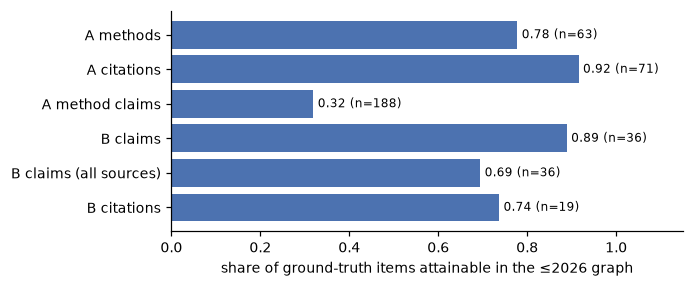

In [9]:
def frac(items, key):
    items = list(items)
    return sum(bool(key(x)) for x in items) / max(1, len(items)), len(items)


kinds = {"A methods": [r for g in GOLD.values() if g["type"] == "A" for r in g["methods"].values()],
         "A citations": [r for g in GOLD.values() if g["type"] == "A" for r in g["citations"].values()],
         "A method claims": [c for g in GOLD.values() if g["type"] == "A" for c in g["method_claims"]],
         "B claims": [c for g in GOLD.values() if g["type"] == "B" for c in g["claims"]],
         "B claims (all sources)": [c for g in GOLD.values() if g["type"] == "B" for c in g["claims"]],
         "B citations": [r for g in GOLD.values() if g["type"] == "B" for r in g["citations"].values()]}
keyf = {"A methods": lambda r: r["nodes"], "A citations": lambda r: r["articles"], "A method claims": lambda c: c["attainable"],
        "B claims": lambda c: c["attainable"], "B claims (all sources)": lambda c: c["strict_attainable"],
        "B citations": lambda r: r["articles"]}
ceil = {k: frac(v, keyf[k]) for k, v in kinds.items()}
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(list(ceil), [f for f, _ in ceil.values()], color="#4c72b0")
for i, (f, n) in enumerate(ceil.values()):
    ax.text(f + 0.01, i, f"{f:.2f} (n={n})", va="center", fontsize=8)
ax.set_xlim(0, 1.15); ax.invert_yaxis(); ax.set_xlabel("share of ground-truth items attainable in the ≤2026 graph")
fig.savefig(FIG / "t6_attainability.png"); plt.show()

In [10]:
# Temporal checks: GT source dates vs as_of, and how many ≤2026 articles may postdate "Feb 2026"
rows = []
for q, v in B.items():
    for k, s in v["sources"].items():
        rows.append({"q": q, "source": k, "date": s["date"], "as_of": v["as_of"], "after as_of": s["date"][:7] > v["as_of"]})
tdf = pd.DataFrame(rows)
print("GT sources dated after their question's as_of:", int(tdf["after as_of"].sum()), "of", len(tdf))
print("articles per year in the ≤2026 snapshot:", dict(sorted(Counter(SNAP[2026].year.values()).items())))
print("articles dated 2026 (cannot be excluded for 'by Feb 2026' with yearly snapshots):",
      sum(y == 2026 for y in SNAP[2026].year.values()))

GT sources dated after their question's as_of: 0 of 19
articles per year in the ≤2026 snapshot: {2013: 3, 2015: 1, 2016: 1, 2017: 3, 2018: 2, 2019: 2, 2020: 4, 2021: 1, 2022: 5, 2023: 10, 2024: 6, 2025: 8, 2026: 6}
articles dated 2026 (cannot be excluded for 'by Feb 2026' with yearly snapshots): 6


**Reading the attainability results:**
- The ceilings are well below 1. Some GT methods are conceptual names ("physics-informed", "hybrid frameworks") or
  specific methods absent from the export (e.g. HamGNN). Several type-B sources are not among the export's papers.
- **Verified:** the resolution rules and the counts above.
- **Assumed:** a resolved node is the method the GT means. Acronym and prefix matches are plausible, not checked by
  hand for every case. Ambiguous citations count as hit if any candidate is returned.
- **Trade-off:** strict tiers undercount real matches, lenient tiers overcount. Both are reported, and the strict
  tier is the headline.

## 5. The hierarchy as a search index

The coarsening algorithm writes, per snapshot, a laminar tree:
- L0 has 15 super-nodes, L1 60, L2 240 (P2 budgets);
- L0–L1 super-nodes carry an LLM label and gloss (P6), L2 has none;
- every leaf (graph node) sits in exactly one L2 super-node (P1).

A drill-down agent can only reach targets whose ancestors it keeps. The **target dispersion** below counts, per
question, how many super-nodes at each level hold at least one target. That count is the smallest beam that could keep
all targets if the ranking were perfect: an **oracle bound**.

This diagnostic uses the ground truth, so it is for understanding only. Choosing the beam from it would fit the test
set.

          2020  2022  2024  2026
L0          15    15    15    15
L1          60    60    60    60
L2         240   240   240   240
labelled    75    75    75    75
leaves    1475  2144  4094  5798
leaves of the answer kinds at ≤2026: {'A': 2524, 'B': 690}


,Q1,Q2,Q3,Q4,Q6,Q7,Q8,Q9,Q10,Q12,Q13,Q14,Q15,Q16,Q17,Q18
L0,5,2,1,1,1,1,1,1,1,6,7,7,2,3,3,4
L1,9,2,2,2,1,1,1,2,1,9,11,11,2,3,4,4
L2,10,3,2,2,1,1,1,2,1,11,12,14,2,3,4,4
targets,15,3,2,2,1,1,1,2,1,20,18,21,25,48,65,101


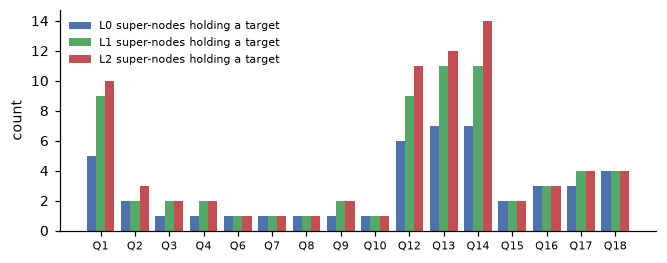

In [11]:
def tree(c):
    h = H[c]
    sn = {s["id"]: s for s in h["supernodes"]}
    children = defaultdict(list)
    for s in h["supernodes"]:
        if s["parent_id"] is not None:
            children[s["parent_id"]].append(s["id"])
    return sn, children


print(pd.DataFrame({c: {f"L{k}": sum(s["level"] == k for s in H[c]["supernodes"]) for k in range(H[c]["levels"])}
                    | {"labelled": sum(bool(s.get("label")) for s in H[c]["supernodes"]),
                       "leaves": len({v for s in H[c]["supernodes"] if s["level"] == 2 for v in s["member_ids"]})}
                    for c in CUTOFFS}))
S26 = SNAP[2026]
print("leaves of the answer kinds at ≤2026:", {t: sum(S26.type[v] in KINDS[t] for v in S26.ids) for t in KINDS})

sn26, _ = tree(2026)
disp = {}
for q, g in GOLD.items():
    t = set(g["targets"])
    if t:
        disp[q] = {f"L{k}": sum(bool(t & set(s["member_ids"])) for s in sn26.values() if s["level"] == k) for k in range(3)}
        disp[q]["targets"] = len(t)
D = pd.DataFrame(disp).T
display(D.T)
fig, ax = plt.subplots(figsize=(7, 2.6))
x = np.arange(len(D))
for k, (lv, col) in enumerate(zip(("L0", "L1", "L2"), ("#4c72b0", "#55a868", "#c44e52"))):
    ax.bar(x + (k - 1) * 0.27, D[lv], width=0.27, label=f"{lv} super-nodes holding a target", color=col)
ax.set_xticks(x, D.index, fontsize=7); ax.set_ylabel("count"); ax.legend(fontsize=7, frameon=False)
fig.savefig(FIG / "t6_target_dispersion.png"); plt.show()

**Reading the dispersion results.** Two regimes appear:
- **Dispersed questions** (Q1, Q2, Q12–Q14 and the synthesis questions Q15–Q18) have targets in 2–8 L0 super-nodes. For
  these, a small L0 beam cannot keep every target even with a perfect ranking, so the coarse grouping by use case
  matters. Intrinsically, coherence at L0 is not supported (`docs/evaluation_report.md` §3).
- **Narrow type-A questions** (Q3, Q4, Q6–Q10) have their 1–2 targets inside a single L0 super-node. Any beam reaches
  them *if the right L0 node ranks in the beam*. For these, reach depends on the routing score, not on dispersion.

Q5 and Q11 have no attainable targets and are left out. Recall should not be the only metric; steps and cost
matter too (§7).

## 6. POC agent: drill-down beam search and flat baseline

**Design choice D4, node content.** All of it is built from the snapshot's own edges (P6).
- **Leaf text:**
  - name and aliases;
  - the names of its relation neighbours over the clustering relations (`addresses`, `solves`, `extends`,
    `uses_component`, `uses_technique`, `evaluated_on`);
  - the `evaluated_on` metric and task;
  - the title of the article that presents it (method, **once**) or claims it (claim);
  - for a presented method, its paper's claims.
- **Super-node content:** label + gloss (L0–L1) and the centroid of its members' leaf vectors.
- *Lesson from an earlier iteration:* `tkh.semantic.attached_text` reads all edges, so it would leak later facts into
  earlier snapshots. A per-claim title loop once repeated a paper's title up to 61 times.

**Design choice D5, similarity.** Word TF-IDF cosine, fitted per snapshot on leaf texts only.
- Clustering used a char-n-gram LSA of names, so this is a different ruler. It is not independent, though: names and
  clustering-relation neighbours are inside the leaf text. That partial overlap is stated, not hidden.
- An embedding model would be stronger on paraphrase, but it is a new dependency and download (rejected for the POC).
- Keyword overlap and BM25 are drop-in alternatives that the implementation can compare under a held-out protocol
  (§9).

**Design choice D6, drill-down.**
- L0–L1 super-node score = 0.5·cos(q, label + gloss) + 0.5·cos(q, centroid); L2 score = cos(q, centroid).
- Beam widths are fixed a priori at 20% of each level's budget: (3, 12, 48) for 15 / 60 / 240. They are not chosen
  from results.
- The pool is the leaves of the kept L2 super-nodes that have the answer kinds, ranked by cos(q, leaf).
- **Consequence, measured in §8:** the beam is a share of the *level's budget*, not of the frontier. L0 nodes have 1–8
  children each, so three kept L0 nodes have at most 21 L1 children together (8 + 7 + 6). L1 therefore keeps 88% of
  its frontier on average and L2 95%. The drill-down is in
  effect "pick 3 of the 15 L0 clusters". The L1 and L2 scores are charged as steps while pruning little. A
  per-frontier fraction is the alternative to fix a priori in the implementation.
- The question is stripped of template words and the date clause before encoding.

**Design choice D7, flat baseline.** The same scorer, leaf texts and answer kinds over every leaf. Only the search
differs, so any difference is the hierarchy's.

**Design choice D8, answer format.** The ground-truth format with k = 10 items, plus the node and article ids the
answer was read from (so scoring needs no string matching):
- **A:** `expected_methods`, `required_citations`, plus `method_claims` and `method_evidence` per returned method,
  read from the graph claims attached to it;
- **B:** `as_of`, `required_claims`, `sources` and `required_citations`.

In [12]:
TEMPLATE = re.compile(r"\((?:by|as of)[^)]*\)|\b(?:which|what|are|is|the|methods?|best|suited|leading|most|"
                      r"important|commonly|used|give|evidences?|when|for|of|by|feb|\d{4})\b", re.I)
BEAM, K = (3, 12, 48), 10


def leaf_texts(S):
    name, title = sm.names(tkh), tkh.articles["title"].to_dict()
    txt = {v: [name[v]] for v in S.ids}
    attrs = S.s.edges["attributes"] if "attributes" in S.s.edges else [None] * len(S.s.edges)
    presented = {}
    for m, r, a, at in zip(S.s.edges["members"], S.s.edges["relation_type"], S.s.edges["article_id"], attrs):
        if r in CLUSTER_RELATIONS:
            txt[m[0]] += [name[t] for t in m[1:]]
            for t in m[1:]:
                txt[t].append(name[m[0]])
            if r == "evaluated_on" and isinstance(at, dict):
                for v in m:
                    txt[v].append(" ".join(str(at[k]) for k in ("metric", "task") if at.get(k)))
        elif r == "presents" and isinstance(title.get(a), str):
            txt[m[1]].append(sm.clean(title[a]))             # once per presented method
            presented[a] = m[1]
        elif r == "claims" and isinstance(title.get(a), str):
            for v in m[1:]:
                if S.type[v] == "claim":
                    txt[v].append(sm.clean(title[a]))
    for a, v in presented.items():
        txt[v] += [S.name[c] for c in S.claims_of[a]]
    return {v: " . ".join(x) for v, x in txt.items()}


class Index:
    # Snapshot search index: leaf TF-IDF, super-node label and centroid vectors, the tree.
    def __init__(self, cutoff, sn=None):
        self.S = SNAP[cutoff]
        base, self.children = tree(cutoff)
        self.sn = sn or base
        self.roots = [i for i, s in self.sn.items() if s["level"] == 0]
        self.leaves = sorted({v for s in self.sn.values() if s["level"] == 2 for v in s["member_ids"]})
        texts = leaf_texts(self.S)
        self.X, self.vec = sm.vectorize([texts[v] for v in self.leaves], kind="word")
        self.row = {v: i for i, v in enumerate(self.leaves)}
        self.set_tree(self.sn)

    def set_tree(self, sn, use_labels=True):
        self.sn = sn
        self.centroid = {i: normalize(np.asarray(self.X[[self.row[v] for v in s["member_ids"]]].mean(axis=0)))[0]
                         for i, s in sn.items()}
        lab = [i for i, s in sn.items() if s.get("label") and use_labels]
        L = normalize(self.vec.transform([f"{sn[i]['label']} . {sn[i].get('gloss') or ''}" for i in lab])) if lab else None
        self.labelvec = {i: L[j].toarray()[0] for j, i in enumerate(lab)}

    def encode(self, question):
        return normalize(self.vec.transform([sm.clean(TEMPLATE.sub(" ", question))])).toarray()[0]

    def score(self, i, q):
        c = float(self.centroid[i] @ q)
        return 0.5 * float(self.labelvec[i] @ q) + 0.5 * c if i in self.labelvec else c

    def rank(self, ids, q):
        ids = sorted(ids)
        s = self.X[[self.row[v] for v in ids]] @ q if ids else np.zeros(0)
        return sorted(zip(ids, map(float, s)), key=lambda t: (-t[1], t[0]))


def descend(ix, q, kinds, beam=BEAM):
    frontier, trace = ix.roots, []
    for level, b in enumerate(beam):
        scored = sorted(((ix.score(i, q), i) for i in frontier), key=lambda t: (-t[0], t[1]))
        keep = [i for _, i in scored[:b]]
        trace += [{"level": level, "id": i, "label": ix.sn[i].get("label"), "score": round(s, 4), "kept": i in keep}
                  for s, i in scored]
        frontier = [c for i in keep for c in ix.children[i]]
    pool = {v for i in keep for v in ix.sn[i]["member_ids"] if ix.S.type[v] in kinds}
    return ix.rank(pool, q), trace


def flat(ix, q, kinds):
    return ix.rank([v for v in ix.leaves if ix.S.type[v] in kinds], q), []

In [13]:
def extract(S, qtype, ranked, as_of):
    # The answer in the ground-truth format, plus the ids it was read from.
    if qtype == "A":
        seen, picked = set(), []
        for v, _ in ranked:
            k = sm.name_key(S.name[v])
            if k and k not in seen:
                seen.add(k); picked.append(v)
            if len(picked) == K:
                break
        claims = {S.name[v]: sorted(S.method_claims[v])[:3] for v in picked}
        arts = list(dict.fromkeys(a for v in picked for a in S.articles_of[v]))
        return {"expected_methods": [S.name[v] for v in picked],
                "method_claims": {m: [S.name[c] for c in cs] for m, cs in claims.items()},
                "method_evidence": {m: [{"source": S.citation(a), "location": c, "evidence": S.name[c]}
                                        for c in cs for a in S.articles_of[c][:1]] for m, cs in claims.items()},
                "required_citations": [S.citation(a) for a in arts],
                "_nodes": picked, "_claim_nodes": {S.name[v]: cs for v, cs in zip(picked, claims.values())}, "_articles": arts}
    picked = [v for v, _ in ranked[:K]]
    arts = list(dict.fromkeys(a for v in picked for a in S.articles_of[v]))
    key = {a: f"{fold(S.citation(a).split(' ')[0])}{S.year[a]}_{a}" for a in arts}
    return {"as_of": as_of,
            "required_claims": [{"id": f"R{i + 1}", "text": S.name[v], "sources": [key[a] for a in S.articles_of[v]]}
                                for i, v in enumerate(picked)],
            "sources": {key[a]: {"key": S.citation(a), "title": S.title.get(a), "date": str(S.year[a])} for a in arts},
            "required_citations": [key[a] for a in arts], "_nodes": picked, "_articles": arts}


class Agent:
    # answer(question, qtype, mode): sees only the question text and its type.
    def __init__(self, index_for=None, beam=BEAM):
        self.ix, self.beam = index_for or {}, beam

    def index(self, c):
        if c not in self.ix:
            self.ix[c] = Index(c)
        return self.ix[c]

    def answer(self, question, qtype, mode="hier"):
        c, year, _ = choose_snapshot(question)
        if c is None:                                    # date before the first cutoff: no admissible snapshot
            return {"abstain": True, "snapshot": None}
        ix = self.index(c)
        q = ix.encode(question)
        ranked, trace = descend(ix, q, KINDS[qtype], self.beam) if mode == "hier" else flat(ix, q, KINDS[qtype])
        out = extract(ix.S, qtype, ranked, f"{year or c}")
        out.update(snapshot=c, ranked=[v for v, _ in ranked], trace=trace, n_scored=len(trace),
                   closest={lv: next((t["id"], t["label"], t["score"]) for t in trace if t["level"] == lv)
                            for lv in sorted({t["level"] for t in trace})})
        if ranked:
            out["closest"]["leaf"] = (ranked[0][0], ix.S.name[ranked[0][0]], round(ranked[0][1], 4))
        return out


agent = Agent()
for qid in ("Q2", "Q15"):
    a = agent.answer(qdf.set_index("question_id").loc[qid, "question"], gt[qid]["type"])
    print(f"{qid} -> snapshot {a['snapshot']}; super-nodes scored {a['n_scored']}; pool {len(a['ranked'])}")
    for lv, (i, lab, s) in a["closest"].items():
        print(f"   closest at {'L' + str(lv) if lv != 'leaf' else 'leaf'}: {i} {lab!r} ({s})")
    show = a["expected_methods"] if gt[qid]["type"] == "A" else [c["text"][:90] for c in a["required_claims"]]
    print("   answer:", show[:5], "\n   citations:", a["required_citations"][:5])

Q2 -> snapshot 2026; super-nodes scored 79; pool 307
   closest at L0: L0.9 'High-throughput DFT methods' (0.0546)
   closest at L1: L1.59 'Density functional techniques' (0.096)
   closest at L2: L2.193 None (0.1748)
   closest at leaf: tech_00106 'AI-accelerated electronic structure prediction' (0.1142)
   answer: ['AI-accelerated electronic structure prediction', 'High-throughput DFT calculations', 'DBS electronic minimizer', 'RMM-DIIS electronic minimizer', 'high-throughput calculations'] 
   citations: ['Maevskiy et al. 2026', 'Schmidt et al. 2022', 'Curtarolo et al. 2015', 'Schoenholz et al. 2023', 'Zitnick et al. 2026']
Q15 -> snapshot 2026; super-nodes scored 85; pool 220
   closest at L0: L0.8 'Graph Neural Networks' (0.0912)
   closest at L1: L1.27 'Crystal-Graph Attention Networks' (0.0973)
   closest at L2: L2.300 None (0.3222)
   closest at leaf: clai_00357 'Current challenges limiting AI-driven multiscale modeling include limited data availability, restricted model transf

In [14]:
# P6 check on an earlier snapshot (all 18 questions use ≤2026, so this exercises the temporal path explicitly):
# a method published after 2020 that extends a ≤2020 node must not appear in that node's ≤2020 text or vocabulary.
S20, S26 = SNAP[2020], SNAP[2026]
t20, t26 = leaf_texts(S20), leaf_texts(S26)
late = S26.s.edges[(S26.s.edges["article_year"] > 2020) & (S26.s.edges["relation_type"] == "extends")]
pairs = [(t, m[0]) for m in late["members"] for t in m[1:] if t in S20.s.node_ids and S20.name[m[0]] not in t20[t]]
assert pairs and all(S26.name[h] in t26[t] for t, h in pairs)
ix20 = Index(2020)
late_only = {w for t, h in pairs for w in re.findall(r"[a-z][a-z0-9\-]{3,}", S26.name[h].lower())} - \
            {w for x in t20.values() for w in re.findall(r"[a-z][a-z0-9\-]{3,}", x.lower())}
assert not late_only & set(ix20.vec.vocabulary_), "later vocabulary leaked into the ≤2020 index"
print(f"P6 check: {len(pairs)} later 'extends' facts absent from ≤2020 texts; {len(late_only)} later-only words absent "
      f"from the ≤2020 vocabulary. Known gap: aliases have no date and are taken from the whole export.")

P6 check: 52 later 'extends' facts absent from ≤2020 texts; 26 later-only words absent from the ≤2020 vocabulary. Known gap: aliases have no date and are taken from the whole export.


## 7. Metric design

The unit is the question. Type A (n = 14) is the main set; type B (n = 4) is descriptive. All metrics are computed on
attainable items only, and the ceilings (§4) are reported beside them.

### Hit-rate (accuracy)

**M1, item hit-rate @k.** The share of a question's attainable GT items found in its k = 10 answer.
- **Methods (A):** a GT method is hit if the answer contains one of its resolved nodes or a node with the same
  `name_key`. Reported on the strict tier (exact + acronym) and the lenient tier (+ prefix).
- **Citations (A, B):** a GT citation is hit if one of its resolved articles is among the answer's cited articles.
- **Claims (B):** a required claim is hit if the answer returns any claim of one of its source articles
  (source-grounded). It is a **strict** hit if the returned claims cover *every* source of the claim.
  Until a content judge exists, the B claim hit is in effect a source-level hit.
- **Method claims (A):** attainable if the graph links a claim from the method's evidence article to a resolved node
  of the method (§4). It is hit if the method is hit *and* a graph claim returned for that method comes from that
  article.

This is source-grounded, not content-grounded. The GT claims are paraphrases, so matching their *content* needs a
semantic judge. That is proposed in §9 and not run here.

**M2, precision side (A, where `fp_categories` exists):**
- error rate = the share of the k answers that resolve to `wrong_domain` or `outdated_as_main` names;
- `valid_but_unlisted` answers are neutral, so the GT is not treated as exhaustive.

Without M2, a retriever that returns many plausible-but-wrong methods looks as good as one that returns correct ones.

**M3, breadth control.** The number of distinct articles an answer cites, and citation precision = citation hits ÷
articles cited. *Lesson from an earlier iteration:* citation hit-rate rose with breadth alone (3 → 11 articles per
answer), while citation precision barely moved.

**M4, temporal compliance.** The share of cited articles with year ≤ the *evaluator's* as-of year: the GT `as_of`
for B, and the evaluator's own parse of the question for A. A separate check confirms that the agent's snapshot equals
the expected one (`snapshot_ok`). Both are 1 when the snapshot rule holds, which makes them a regression test for P6.

### Steps-to-target (cost)

**M5, steps-to-target.** One step is one node the agent inspects.
- **Targets are GT items**, not nodes. For A, each attainable GT method on the strict tier counts once, found at the
  first of its nodes; for B, each attainable required claim counts once, found at the first claim of its source
  articles.
- **Drill-down:** every super-node scored on the way down, plus the rank of the item in the pool.
- **Flat:** the item's rank among all leaves of the answer kinds.
- An item not in the drill-down pool is **censored** at N + 1 (N = the number of flat candidates: 2524 for A, 690
  for B).
- Reported to the first item and to 50% of the items, as **medians** with the share of questions reaching an item.
  Means are not reported, because the censor value would set their size.

**Why steps alone are not enough.** The pool is a subset of the flat candidates scored by the same function, so a
target's rank in the pool is never worse than its global rank. The drill-down can lose only by dropping the target or
by the super-node overhead, and any random subset of the same size would show the same rank gain.

**M6, budget-matched recall.** recall(s) = the share of a question's GT items found within the first s nodes inspected,
for s = 1…1000, with its area under the curve. The drill-down spends its first steps on super-nodes. This curve
compares both systems at equal cost, and it is the headline comparison.

### Nulls and ablation (relative to chance)

**M7, random-tree null.** The leaves are permuted across L2 super-nodes, keeping their sizes and the tree shape above,
and labels stay attached to their super-node ids (R = 20 permutations). This tests whether the *grouping* helps beyond
any subset of the same shape.

**M8, label-free ablation.** The label term is dropped (centroid only). This isolates the contribution of the T5
labels.

### Statistics

- **M9.** Paired bootstrap over questions (B = 2000) for drill-down − flat and real − null, with 95% percentile CIs.
  The systems answer the same questions, hence the pairing. With n = 14 + 4, CIs are wide and stated as such.
- **Leakage guard.** The agent receives only `(question, type)`, and ground truth lives in the evaluator. §8 checks
  this in two ways: structurally (the agent's code names no ground-truth object) and behaviourally (with the
  ground-truth objects removed from the namespace, the answers are identical).

| Rejected alternative | Why |
|---|---|
| Raw recall against all GT items | Mixes graph coverage with retrieval failure |
| Steps counting only leaves | Hides the routing cost and favours the hierarchy |
| Dropping misses from steps | Hides routing failures |
| A fixed flat baseline with a different scorer | Credits the hierarchy with the scorer's gains |
| Lexical threshold for claim content | Arbitrary threshold, weak on paraphrase; source grounding is deterministic, and a judge is the principled upgrade |
| Tuning beam/k on the 18 questions | Fits the test set; settings are fixed a priori, and alternatives are compared under LOO or held-out questions only |

In [15]:
def score(ans, g, S):
    out = {}
    got_nodes, got_keys = set(ans["_nodes"]), {sm.name_key(S.name[v]) for v in ans["_nodes"]}
    cited = set(ans["_articles"])
    rate = lambda hits: (sum(hits) / len(hits)) if hits else None   # noqa: E731
    if g["type"] == "A":
        hit_m = {m: bool(set(r["nodes"]) & got_nodes or {sm.name_key(S.name[v]) for v in r["nodes"]} & got_keys)
                 for m, r in g["methods"].items() if r["nodes"]}
        out["methods"] = rate(list(hit_m.values()))
        out["methods_strict"] = rate([hit_m[m] for m, r in g["methods"].items() if r["nodes"] and r["tier"] in ("exact", "acronym")])
        mc = []
        for c in g["method_claims"]:
            if c["attainable"] and hit_m.get(c["method"]):
                names = {S.name[v] for v in g["methods"][c["method"]]["nodes"]}
                ret = [x for m, xs in ans["_claim_nodes"].items() if m in names for x in xs]
                mc.append(any(set(S.articles_of[x]) & set(c["articles"]) for x in ret))
            elif c["attainable"]:
                mc.append(False)
        out["method_claims"] = rate(mc)
        if g["fp"]:
            wrong = {v for cat in ("wrong_domain", "outdated_as_main") for ns in g["fp"].get(cat, {}).values() for v in ns}
            wrong_keys = {sm.name_key(S.name[v]) for v in wrong}
            out["error_rate"] = sum(v in wrong or sm.name_key(S.name[v]) in wrong_keys for v in ans["_nodes"]) / max(1, len(ans["_nodes"]))
    else:
        arts_returned = {a for v in ans["_nodes"] for a in S.articles_of[v]}
        out["claims"] = rate([bool(set(c["articles"]) & arts_returned) for c in g["claims"] if c["attainable"]])
        out["claims_strict"] = rate([all(set(xs) & arts_returned for xs in c["per_source"].values())
                                     for c in g["claims"] if c["strict_attainable"]])
    cits = [bool(set(r["articles"]) & cited) for r in g["citations"].values() if r["articles"]]
    out["citations"] = rate(cits)
    out["n_articles"] = len(cited)
    out["citation_precision"] = sum(cits) / max(1, len(cited))
    # P6, graded against the evaluator's own reference (GT as_of for B, the evaluator's parse for A)
    out["snapshot_ok"] = ans["snapshot"] == g["expected_snapshot"]
    out["temporal_compliance"] = sum(S.year[a] <= g["as_of_year"] for a in cited) / max(1, len(cited))
    # steps: inspected sequence = super-nodes scored, then the ranked pool; one target per GT item
    items, n_flat = g["step_items"], sum(S.type[v] in KINDS[g["type"]] for v in S.ids)
    pos = {v: i + 1 for i, v in enumerate(ans["ranked"])}
    found = sorted(min(pos[v] for v in it if v in pos) for it in items if any(v in pos for v in it))
    if items:
        out["reached"] = bool(found)
        out["steps_first"] = ans["n_scored"] + found[0] if found else n_flat + 1
        half = int(np.ceil(len(items) / 2))
        out["steps_half"] = ans["n_scored"] + found[half - 1] if len(found) >= half else n_flat + 1
        out["curve"] = [sum(ans["n_scored"] + r <= s for r in found) / len(items) for s in BUDGET]
    return out


BUDGET = np.unique(np.round(np.logspace(0, 3, 60)).astype(int))


def run(agent, mode, gold=GOLD):
    res = {}
    for qid, row in qdf.set_index("question_id").iterrows():
        a = agent.answer(row["question"], row["type"], mode)
        res[qid] = {"answer": a} if a.get("abstain") else {"answer": a, **score(a, gold[qid], agent.index(a["snapshot"]).S)}
    return res


def boot(x, B=2000, seed=0, stat=np.mean):
    x = np.asarray([v for v in x if v is not None], float)
    if not len(x):
        return (np.nan, np.nan, np.nan, 0)
    b = stat(x[np.random.default_rng(seed).integers(0, len(x), (B, len(x)))], axis=1)
    return (float(stat(x)), *np.quantile(b, [0.025, 0.975]), len(x))

## 8. POC results on all 18 questions

Both systems run on every question. Then the leakage guard is checked, the summary is shown with paired CIs, and the
budget-matched curves, steps, nulls and ablation follow.

In [16]:
HIER, FLAT = run(agent, "hier"), run(agent, "flat")

# leakage guard (structural + behavioural): the agent's code names no ground-truth object, and it gives the same
# answers when the ground-truth objects are removed from the namespace
names = set()


def _names(co):
    names.update(co.co_names)
    for c in co.co_consts:
        if hasattr(c, "co_names"):
            _names(c)


for f in (choose_snapshot, leaf_texts, descend, flat, extract, tree, Agent.__init__, Agent.index, Agent.answer,
          Index.__init__, Index.set_tree, Index.encode, Index.score, Index.rank, Snap.__init__, Snap.citation):
    _names(f.__code__)
FORBIDDEN = {"gt", "GOLD", "A", "B", "resolve_gold", "GT_PATH"}   # ("score" is also the agent's own method name)
assert not names & FORBIDDEN, names & FORBIDDEN
hidden = {k: globals().pop(k) for k in ("gt", "GOLD", "A", "B")}
try:
    blind = {qid: Agent(agent.ix).answer(r["question"], r["type"])["_nodes"] for qid, r in qdf.set_index("question_id").iterrows()}
finally:
    globals().update(hidden)
assert all(blind[q] == HIER[q]["answer"]["_nodes"] for q in blind)
print("leakage guard: agent code references no ground truth; answers identical with ground truth removed")

METRICS = {"A": ["methods", "methods_strict", "method_claims", "citations", "error_rate", "n_articles", "citation_precision",
                 "temporal_compliance", "snapshot_ok", "reached", "steps_first", "steps_half"],
           "B": ["claims", "claims_strict", "citations", "n_articles", "citation_precision", "temporal_compliance",
                 "snapshot_ok", "reached", "steps_first", "steps_half"]}


def summary(sysA, sysB, names=("drill-down", "flat")):
    rows = []
    for t, ms in METRICS.items():
        qs = [q for q in HIER if gt[q]["type"] == t]
        for m in ms:
            pa = [(sysA[q].get(m), sysB[q].get(m)) for q in qs]
            pa = [(float(x), float(y)) for x, y in pa if x is not None and y is not None]
            st = np.median if m.startswith("steps") else np.mean      # censored steps: medians, not means
            a, b, d = boot([x for x, _ in pa], stat=st), boot([y for _, y in pa], stat=st), boot([x - y for x, y in pa], stat=st)
            rows.append({"type": t, "metric": m + (" (median)" if st is np.median else ""), "n": a[3],
                         names[0]: f"{a[0]:.3f}", names[1]: f"{b[0]:.3f}",
                         f"{names[0]} − {names[1]} [95% CI]": f"{d[0]:+.3f} [{d[1]:+.3f}, {d[2]:+.3f}]"})
    return pd.DataFrame(rows).set_index(["type", "metric"])


SUM = summary(HIER, FLAT)
SUM

leakage guard: agent code references no ground truth; answers identical with ground truth removed


n drill-down     flat  \
type metric                                         
A    methods               12      0.042    0.174   
     methods_strict        12      0.042    0.175   
     method_claims          9      0.000    0.222   
     citations             14      0.273    0.366   
     error_rate            12      0.008    0.008   
     n_articles            14      6.714    6.786   
     citation_precision    14      0.239    0.193   
     temporal_compliance   14      1.000    1.000   
     snapshot_ok           14      1.000    1.000   
     reached               12      0.583    1.000   
     steps_first (median)  12    239.000   34.500   
     steps_half (median)   12   2525.000  119.500   
B    claims                 4      0.261    0.604   
     claims_strict          4      0.119    0.326   
     citations              4      0.250    0.438   
     n_articles             4      3.750    5.250   
     citation_precision     4      0.286    0.321   
     temporal_compliance    4      1.000    1.000   
     snapshot_ok            4      1.000    1.000   
     reached                4      0.750    1.000   
     steps_first (median)   4     88.500    2.500   
     steps_half (median)    4    392.000    5.000   

                                drill-down − flat [95% CI]  
type metric                                                 
A    methods                       -0.133 [-0.307, +0.000]  
     methods_strict                -0.133 [-0.308, +0.000]  
     method_claims                 -0.222 [-0.556, +0.000]  
     citations                     -0.093 [-0.324, +0.121]  
     error_rate                    +0.000 [+0.000, +0.000]  
     n_articles                    -0.071 [-1.000, +0.857]  
     citation_precision            +0.047 [-0.092, +0.194]  
     temporal_compliance           +0.000 [+0.000, +0.000]  
     snapshot_ok                   +0.000 [+0.000, +0.000]  
     reached                       -0.417 [-0.667, -0.167]  
     steps_first (median)    +112.000 [+62.000, +2453.500]  
     steps_half (median)   +2187.000 [+203.000, +2453.500]  
B    claims                        -0.343 [-0.686, +0.000]  
     claims_strict                 -0.207 [-0.414, +0.000]  
     citations                     -0.188 [-0.375, +0.000]  
     n_articles                    -1.500 [-3.000, +0.000]  
     citation_precision            -0.036 [-0.250, +0.214]  
     temporal_compliance           +0.000 [+0.000, +0.000]  
     snapshot_ok                   +0.000 [+0.000, +0.000]  
     reached                       -0.250 [-0.750, +0.000]  
     steps_first (median)      +87.000 [+66.000, +685.000]  
     steps_half (median)      +384.000 [+52.000, +689.000]

In [17]:
def per_q(res):
    return pd.DataFrame({q: {k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()
                             if k not in ("answer", "curve")} | {"pool": len(r["answer"]["ranked"]), "scored": r["answer"]["n_scored"]}
                         for q, r in res.items()}).T


pq = per_q(HIER).add_prefix("hier:").join(per_q(FLAT).add_prefix("flat:"))
cols = [c for c in pq.columns if any(c.endswith(x) for x in (":methods", ":claims", ":citations", ":steps_first", ":reached", "hier:pool", "hier:scored"))]
pq[cols]

,hier:methods,hier:citations,hier:reached,hier:steps_first,hier:pool,hier:scored,hier:claims,flat:methods,flat:citations,flat:reached,flat:steps_first,flat:claims
Q1,0.0,0.14,True,222,575,69,NaN,0.0,0.14,True,98,NaN
Q2,0.5,0.0,True,89,307,79,NaN,0.5,0.43,True,10,NaN
Q3,0.0,0.0,False,2525,569,85,NaN,0.5,1.0,True,7,NaN
Q4,0.0,0.67,False,2525,285,79,NaN,0.0,0.0,True,106,NaN
Q5,None,0.0,NaN,NaN,397,68,NaN,None,0.0,NaN,NaN,NaN
Q6,0.0,0.67,False,2525,491,77,NaN,1.0,0.67,True,10,NaN
Q7,0.0,0.0,False,2525,349,57,NaN,0.0,1.0,True,1266,NaN
Q8,0.0,0.5,True,81,406,70,NaN,0.0,0.5,True,18,NaN
Q9,0.0,1.0,False,2525,433,89,NaN,0.0,1.0,True,37,NaN
Q10,0.0,0.25,True,256,357,51,NaN,0.0,0.0,True,1252,NaN


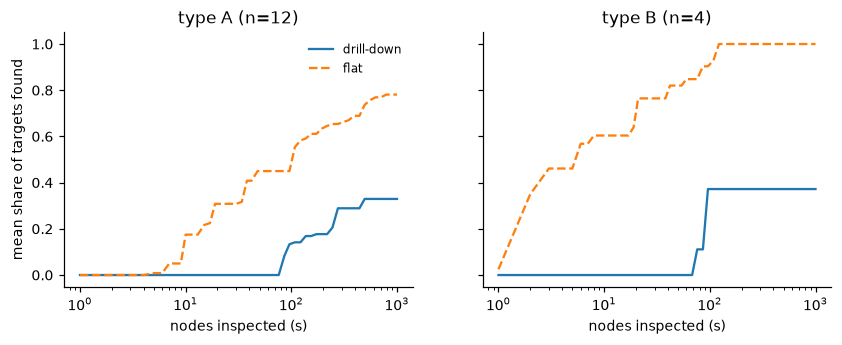

normalised area under recall(log s): {'drill-down': {'A': 0.087, 'B': 0.133}, 'flat': {'A': 0.343, 'B': 0.716}}


In [18]:
def mean_curve(res, qs):
    return np.mean([res[q]["curve"] for q in qs if "curve" in res[q]], axis=0)


fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, t in zip(axes, ("A", "B")):
    qs = [q for q in HIER if gt[q]["type"] == t and "curve" in HIER[q]]
    for res, lab, st in ((HIER, "drill-down", "-"), (FLAT, "flat", "--")):
        ax.plot(BUDGET, mean_curve(res, qs), st, label=lab)
    ax.set_xscale("log"); ax.set_title(f"type {t} (n={len(qs)})"); ax.set_xlabel("nodes inspected (s)")
axes[0].set_ylabel("mean share of targets found"); axes[0].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "t6_budget_recall.png"); plt.show()

auc = {name: {t: float(np.trapezoid(mean_curve(res, [q for q in res if gt[q]["type"] == t and "curve" in res[q]]), np.log(BUDGET)) / np.log(BUDGET[-1]))
              for t in ("A", "B")} for name, res in (("drill-down", HIER), ("flat", FLAT))}
print("normalised area under recall(log s):", pd.DataFrame(auc).round(3).to_dict())

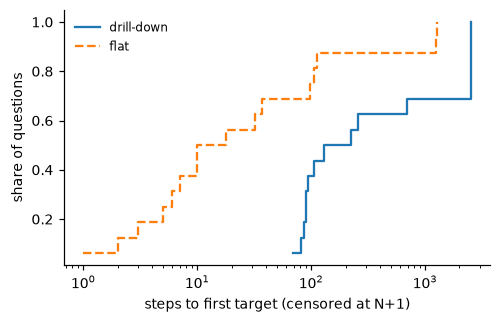

In [19]:
fig, ax = plt.subplots(figsize=(5, 3))
for res, lab, st in ((HIER, "drill-down", "-"), (FLAT, "flat", "--")):
    s = np.sort([r["steps_first"] for r in res.values() if "steps_first" in r])
    ax.step(s, np.arange(1, len(s) + 1) / len(s), st, where="post", label=lab)
ax.set_xscale("log"); ax.set_xlabel("steps to first target (censored at N+1)"); ax.set_ylabel("share of questions")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "t6_steps_ecdf.png"); plt.show()

In [20]:
# Nulls: random trees (leaves permuted across L2, shape and labels kept) and the label-free ablation
ix = agent.index(2026)
base_sn = ix.sn


def random_tree(sn, rng):
    l2 = sorted(i for i, s in sn.items() if s["level"] == 2)
    leaves = [v for i in l2 for v in sn[i]["member_ids"]]
    perm = rng.permutation(leaves)
    new, pos = {i: dict(s) for i, s in sn.items()}, 0
    for i in l2:
        n = len(sn[i]["member_ids"]); new[i]["member_ids"] = list(perm[pos:pos + n]); pos += n
    for lv in (1, 0):                                    # parents = union of their children's members
        for i, s in new.items():
            if s["level"] == lv:
                s["member_ids"] = [v for c in ix.children[i] for v in new[c]["member_ids"]]
    return new


null_runs = []
for r in range(20):
    ix.set_tree(random_tree(base_sn, np.random.default_rng(r)))
    null_runs.append(run(agent, "hier"))
ix.set_tree(base_sn, use_labels=False); NOLAB = run(agent, "hier")
ix.set_tree(base_sn); assert run(agent, "hier")["Q1"]["answer"]["_nodes"] == HIER["Q1"]["answer"]["_nodes"]


def avg_null(metric, q):
    vals = [nr[q].get(metric) for nr in null_runs if nr[q].get(metric) is not None]
    return float(np.mean(vals)) if vals else None


NULL = {q: {m: avg_null(m, q) for m in set(METRICS["A"]) | set(METRICS["B"])} for q in HIER}
display(summary(HIER, NULL, ("drill-down", "random-tree null (mean of 20)")))
display(summary(HIER, NOLAB, ("drill-down", "no labels")))

n drill-down random-tree null (mean of 20)  \
type metric                                                              
A    methods               12      0.042                         0.081   
     methods_strict        12      0.042                         0.080   
     method_claims          9      0.000                         0.061   
     citations             14      0.273                         0.339   
     error_rate            12      0.008                         0.005   
     n_articles            14      6.714                         7.750   
     citation_precision    14      0.239                         0.168   
     temporal_compliance   14      1.000                         1.000   
     snapshot_ok           14      1.000                         1.000   
     reached               12      0.583                         0.513   
     steps_first (median)  12    239.000                      1439.875   
     steps_half (median)   12   2525.000                      2059.575   
B    claims                 4      0.261                         0.533   
     claims_strict          4      0.119                         0.344   
     citations              4      0.250                         0.438   
     n_articles             4      3.750                         6.562   
     citation_precision     4      0.286                         0.233   
     temporal_compliance    4      1.000                         1.000   
     snapshot_ok            4      1.000                         1.000   
     reached                4      0.750                         1.000   
     steps_first (median)   4     88.500                        79.425   
     steps_half (median)    4    392.000                        88.875   

                          drill-down − random-tree null (mean of 20) [95% CI]  
type metric                                                                    
A    methods                                          -0.039 [-0.112, +0.037]  
     methods_strict                                   -0.039 [-0.112, +0.038]  
     method_claims                                    -0.061 [-0.133, -0.011]  
     citations                                        -0.066 [-0.244, +0.113]  
     error_rate                                       +0.003 [-0.005, +0.015]  
     n_articles                                       -1.036 [-2.275, +0.239]  
     citation_precision                               +0.071 [-0.041, +0.216]  
     temporal_compliance                              +0.000 [+0.000, +0.000]  
     snapshot_ok                                      +0.000 [+0.000, +0.000]  
     reached                                          +0.071 [-0.154, +0.329]  
     steps_first (median)                        -45.425 [-663.175, +522.125]  
     steps_half (median)                       +239.400 [-1479.950, +581.025]  
B    claims                                           -0.272 [-0.450, -0.082]  
     claims_strict                                    -0.225 [-0.400, -0.019]  
     citations                                        -0.188 [-0.275, -0.100]  
     n_articles                                       -2.812 [-4.475, -1.362]  
     citation_precision                               +0.053 [-0.110, +0.215]  
     temporal_compliance                              +0.000 [+0.000, +0.000]  
     snapshot_ok                                      +0.000 [+0.000, +0.000]  
     reached                                          -0.250 [-0.750, +0.000]  
     steps_first (median)                           +5.475 [-0.800, +613.450]  
     steps_half (median)                         +300.125 [-50.900, +606.700]

n drill-down no labels  \
type metric                                          
A    methods               12      0.042     0.208   
     methods_strict        12      0.042     0.208   
     method_claims          9      0.000     0.111   
     citations             14      0.273     0.292   
     error_rate            12      0.008     0.008   
     n_articles            14      6.714     6.000   
     citation_precision    14      0.239     0.219   
     temporal_compliance   14      1.000     1.000   
     snapshot_ok           14      1.000     1.000   
     reached               12      0.583     0.583   
     steps_first (median)  12    239.000   118.000   
     steps_half (median)   12   2525.000  1481.000   
B    claims                 4      0.261     0.261   
     claims_strict          4      0.119     0.119   
     citations              4      0.250     0.250   
     n_articles             4      3.750     4.000   
     citation_precision     4      0.286     0.225   
     temporal_compliance    4      1.000     1.000   
     snapshot_ok            4      1.000     1.000   
     reached                4      0.750     0.750   
     steps_first (median)   4     88.500    90.000   
     steps_half (median)    4    392.000   402.500   

                          drill-down − no labels [95% CI]  
type metric                                                
A    methods                      -0.167 [-0.417, +0.000]  
     methods_strict               -0.167 [-0.417, +0.000]  
     method_claims                -0.111 [-0.333, +0.000]  
     citations                    -0.019 [-0.209, +0.143]  
     error_rate                   +0.000 [+0.000, +0.000]  
     n_articles                   +0.714 [-0.500, +2.071]  
     citation_precision           +0.021 [-0.050, +0.090]  
     temporal_compliance          +0.000 [+0.000, +0.000]  
     snapshot_ok                  +0.000 [+0.000, +0.000]  
     reached                      +0.000 [-0.333, +0.333]  
     steps_first (median)        +0.000 [-9.500, +51.500]  
     steps_half (median)       +0.000 [+0.000, +1144.500]  
B    claims                       +0.000 [+0.000, +0.000]  
     claims_strict                +0.000 [+0.000, +0.000]  
     citations                    +0.000 [+0.000, +0.000]  
     n_articles                   -0.250 [-2.250, +1.500]  
     citation_precision           +0.061 [-0.043, +0.225]  
     temporal_compliance          +0.000 [+0.000, +0.000]  
     snapshot_ok                  +0.000 [+0.000, +0.000]  
     reached                      +0.000 [+0.000, +0.000]  
     steps_first (median)        -0.500 [-23.000, +5.000]  
     steps_half (median)         -0.500 [-21.000, +0.000]

,reached,mean steps_first,A methods,A citations,B claims,mean super-nodes scored
beam,,,,,,
1/1/1,0,2066.500,0.000,0.083,0.000,24.278
2/6/24,5,1424.688,0.008,0.182,0.111,48.778
3/12/48,10,908.562,0.042,0.273,0.261,73.389
5/20/80,13,528.250,0.208,0.354,0.261,116.056
8/30/120,15,434.688,0.208,0.335,0.404,177.722
15/60/240,16,500.375,0.174,0.366,0.604,315.000


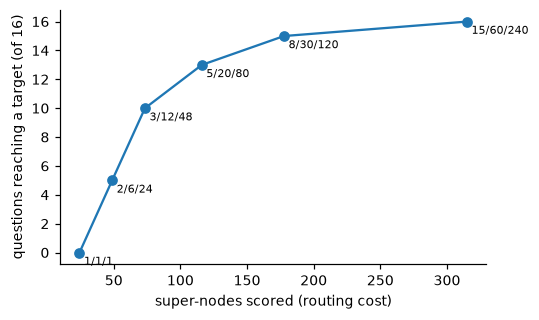

In [21]:
# Beam width as a cost/reach trade-off (shown, not used to choose the POC setting)
widths = [(1, 1, 1), (2, 6, 24), (3, 12, 48), (5, 20, 80), (8, 30, 120), (15, 60, 240)]
rows = []
for b in widths:
    res = run(Agent(agent.ix, beam=b), "hier")
    qs = [q for q in res if "steps_first" in res[q]]
    rows.append({"beam": "/".join(map(str, b)), "reached": sum(res[q]["reached"] for q in qs),
                 "mean steps_first": np.mean([res[q]["steps_first"] for q in qs]),
                 "A methods": np.nanmean([res[q]["methods"] for q in res if gt[q]["type"] == "A" and res[q].get("methods") is not None]),
                 "A citations": np.nanmean([res[q]["citations"] for q in res if gt[q]["type"] == "A" and res[q].get("citations") is not None]),
                 "B claims": np.nanmean([res[q]["claims"] for q in res if gt[q]["type"] == "B" and res[q].get("claims") is not None]),
                 "mean super-nodes scored": np.mean([res[q]["answer"]["n_scored"] for q in res])})
BW = pd.DataFrame(rows).set_index("beam")
display(BW)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(BW["mean super-nodes scored"], BW["reached"], "o-")
for lab, r in BW.iterrows():
    ax.annotate(lab, (r["mean super-nodes scored"], r["reached"]), fontsize=7, xytext=(3, -8), textcoords="offset points")
ax.set_xlabel("super-nodes scored (routing cost)"); ax.set_ylabel(f"questions reaching a target (of {len(qs)})")
fig.savefig(FIG / "t6_beam_tradeoff.png"); plt.show()

In [22]:
# Key numbers for §9 (printed so the text can be checked against them)
qa = [q for q in HIER if gt[q]["type"] == "A" and "steps_first" in HIER[q]]
qb = [q for q in HIER if gt[q]["type"] == "B" and "steps_first" in HIER[q]]
print(f"questions with targets: A {len(qa)}, B {len(qb)}")
for name, res in (("drill-down", HIER), ("flat", FLAT), ("no labels", NOLAB)):
    print(f"{name:10s} reached A {sum(res[q]['reached'] for q in qa)}/{len(qa)}, B {sum(res[q]['reached'] for q in qb)}/{len(qb)}; "
          f"median steps_first A {np.median([res[q]['steps_first'] for q in qa]):.0f}, B {np.median([res[q]['steps_first'] for q in qb]):.0f}")
print("null reached (mean of 20): A", np.mean([sum(nr[q]["reached"] for q in qa) for nr in null_runs]),
      "B", np.mean([sum(nr[q]["reached"] for q in qb) for nr in null_runs]))
print("temporal compliance min (drill-down, flat):", min(r["temporal_compliance"] for r in HIER.values()),
      min(r["temporal_compliance"] for r in FLAT.values()), "; snapshot as expected:", all(r["snapshot_ok"] for r in HIER.values()))
kf = {lv: [] for lv in (0, 1, 2)}
for r in HIER.values():
    for lv in kf:
        sc = [t for t in r["answer"]["trace"] if t["level"] == lv]
        kf[lv].append(sum(t["kept"] for t in sc) / len(sc))
print("kept / frontier per level (mean, min-max):", {f"L{lv}": (round(np.mean(v), 2), round(min(v), 2), round(max(v), 2)) for lv, v in kf.items()})
print("super-nodes scored per question (min-max):", min(r["answer"]["n_scored"] for r in HIER.values()),
      max(r["answer"]["n_scored"] for r in HIER.values()))
for name, res in (("no labels", NOLAB),):
    gain = [q for q in qa + qb if res[q]["reached"] and not HIER[q]["reached"]]
    loss = [q for q in qa + qb if HIER[q]["reached"] and not res[q]["reached"]]
    print(f"{name}: newly reached {gain}, no longer reached {loss}")
print("drill-down never reaches:", [q for q in qa + qb if not HIER[q]["reached"]])

questions with targets: A 12, B 4
drill-down reached A 7/12, B 3/4; median steps_first A 239, B 88
flat       reached A 12/12, B 4/4; median steps_first A 34, B 2
no labels  reached A 7/12, B 3/4; median steps_first A 118, B 90
null reached (mean of 20): A 6.15 B 4.0
temporal compliance min (drill-down, flat): 1.0 1.0 ; snapshot as expected: True
kept / frontier per level (mean, min-max): {'L0': (np.float64(0.2), 0.2, 0.2), 'L1': (np.float64(0.88), 0.57, 1.0), 'L2': (np.float64(0.95), 0.83, 1.0)}
super-nodes scored per question (min-max): 51 89
no labels: newly reached ['Q3', 'Q6'], no longer reached ['Q10', 'Q13']
drill-down never reaches: ['Q3', 'Q4', 'Q6', 'Q7', 'Q9', 'Q17']


## 9. Findings, trade-offs and guidelines for the implementation

### What the POC shows

Numbers are from the cells above, at the a-priori beam (3, 12, 48). There are 12 type-A and 4 type-B questions with
targets, so the CIs are wide, type B is descriptive, and several hit-rate CIs touch zero.

- **Reach is significantly worse.** The drill-down reaches a GT item on 7 of 12 A questions and 3 of 4 B questions;
  flat search reaches one on all 16. The paired difference in reach share for A is −0.417 [−0.667, −0.167].
- **Accuracy: the point estimates favour flat search, and every hit-rate CI touches or includes zero.**
  - Type-A method hit-rate: 0.042 vs 0.174 (−0.133 [−0.307, +0.000]).
  - Type-A citations: 0.273 vs 0.366.
  - Type-B claims: 0.261 vs 0.604.
  - Type-A method claims: 0.000 vs 0.222, on the 9 questions with any attainable method claim.
- **Cost: more steps.** The drill-down scores 51–89 super-nodes before its first leaf.
  - Median steps to the first item: A 239 vs 34.5 (paired median difference +112 [+62, +2453.5]); B 88.5 vs 2.5.
  - The budget-matched recall curve is never above flat search. Both are 0 for type A at s ≤ 4, and the drill-down is
    below from there on (every budget for B). Normalised AUC: A 0.087 vs 0.343, B 0.133 vs 0.716.
- **Relative to chance, the grouping does not help this retriever.**
  - Type A: the random-tree null is not distinguishable on methods (0.081 vs 0.042, CI includes zero). It is better on
    method claims (−0.061 [−0.133, −0.011]).
  - Type B: the null is better on claims (0.533 vs 0.261, −0.272 [−0.450, −0.082]).
  - A plausible reading, not tested here: a random tree samples claims from every topic, whereas the real tree
    concentrates the pool in a few clusters. This is consistent with the null citing more articles (6.6 vs 3.8 for B).
- **Labels: inconclusive.** Without the label term, the drill-down reaches the same number of questions (7/12 A,
  3/4 B), but different ones: it gains Q3 and Q6 and loses Q10 and Q13. Type-A method hit-rate rises from 0.042 to
  0.208, driven by Q3 and Q6 alone, and the CI includes zero.
- **The misses are routing errors at L0.** Of the six questions the drill-down never reaches, five type-A ones (Q3,
  Q4, Q6, Q7, Q9) have their targets inside a single L0 super-node (§5); the lexical score ranks that node outside the
  3 kept. Q17 is the sixth (type B).
  - Reach grows with the beam, from 0 questions (1/1/1) to 16 (full beam).
  - The full beam equals flat search on hit-rate (a consistency check) but costs 315 super-node scores.
  - Better L0 routing (content or scorer) is the first lever; the beam definition (§6, D6) is the second.
- **P6.** Temporal compliance and the snapshot check are 1.0 for every answer. The earlier-snapshot text check passes
  (§6).

These are POC results with a lexical scorer and one a-priori setting. They show that the metric design separates
accuracy, cost and chance. They do not show that hierarchical retrieval cannot help.

### Verified vs assumed

| Verified (this notebook) | Assumed / not verified |
|---|---|
| File formats, field presence and cross-references (§3) | That resolved nodes are the methods the GT means (acronym/prefix tiers) |
| Attainability ceilings under the stated rules (§4) | That a claim from a source article supports the GT claim (source-grounded, not content-checked) |
| Snapshot rule, temporal compliance, earlier-snapshot text check (§2, §6, §8) | That "by Feb 2026" ≈ the ≤2026 snapshot (yearly granularity); that aliases (undated) do not leak |
| Leakage guard: the agent's code names no GT object; answers identical without GT (§8) | That lexical similarity is an adequate proxy for meaning |
| Metric definitions, censoring and pairing as implemented (§7) | That 18 questions represent the intended use |

### Guidelines for the implementation
1. **Modules:**
   - `tkh/retrieve.py`: agent only, sees `(question, type)`;
   - `eval/retrieval.py`: gold resolution (§4), metrics M1–M8, statistics M9;
   - CLI `python -m eval retrieval --run out`, writing `metrics.json["retrieval"]` and `out/retrieval_answers.json`;
   - in `make all` (offline, seconds).
2. **Temporal rule:** every vocabulary, IDF and text comes from the question's snapshot; add a test that a later
   edge never reaches an earlier snapshot's text. Aliases have no date: document this.
3. **Fixed settings:** beam and k are fixed before the first run. Alternatives (scorer: TF-IDF / BM25 / keyword
   overlap; node content; beam) are compared only with leave-one-question-out or held-out questions, and every run is
   reported.
4. **Headline metrics:**
   - item hit-rate (strict tier) and budget-matched recall;
   - steps-to-target with censoring and reach;
   - always paired with ceilings, error rate (M2), breadth (M3) and the random-tree null.
5. **Content matching (next step):** score GT claim *content* (`method_claims`, `required_claims.text`/`evidence`)
   with the cached phi4 entailment judge (`eval/labels.Judge`, numbered-line check against the returned claims).
   - Add a shuffled-answer control for false support.
   - Use `distractor_note` as negative checks.
   - This needs live LLM calls once (consent), then replays offline from `data/llm_cache.json`.
6. **Report:** a field-coverage table (§3), the ceilings, per-question tables, two worked traces (one success, one
   routing failure) and the threats to validity listed below.

### Threats to validity
- n = 18, all on the ≤2026 snapshot, so the temporal dimension of retrieval is untested.
- The lexical scorer is weak on paraphrase.
- Matching is source-level, not content-level.
- Author order is missing from the export.
- Some GT items lie outside the corpus (ceilings).
- Labels exist only at L0–L1.